In [1]:
%pip install scikit-learn

%pip install --upgrade "numpy>=2.0,<2.8" #older version of numpy gets installed with scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import scipy
import sklearn

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.5.4
SciPy: 1.18.1
Scikit-learn: 1.9.1


In [7]:
# Using BEED: Bangalore EEG Epilepsy Dataset from UCI Repository
import pandas as pd

df = pd.read_csv("BEED_Data.csv")

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,y
0,4,7,18,25,28,27,20,10,-10,-18,-20,-16,13,32,12,10,0
1,87,114,120,106,76,54,28,5,-19,-49,-85,-102,-100,-89,-61,-21,0
2,-131,-133,-140,-131,-123,-108,-58,-51,-70,-77,-76,-76,-73,-57,-40,-14,0
3,68,104,73,34,-12,-26,-38,-36,-67,-88,-25,31,18,-4,6,-29,0
4,-67,-90,-97,-94,-86,-71,-43,-11,23,46,58,50,39,19,-9,-41,0


In [9]:
df.shape

(8000, 17)

In [11]:
df.columns

Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11',
       'X12', 'X13', 'X14', 'X15', 'X16', 'y'],
      dtype='object')

In [13]:
df.dtypes

X1     int64
X2     int64
X3     int64
X4     int64
X5     int64
X6     int64
X7     int64
X8     int64
X9     int64
X10    int64
X11    int64
X12    int64
X13    int64
X14    int64
X15    int64
X16    int64
y      int64
dtype: object

In [15]:
df['y'].value_counts().sort_index()

y
0    2000
1    2000
2    2000
3    2000
Name: count, dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(0)

In [19]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,y
count,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,-1.490375,-2.189375,-3.23750,-4.119375,-1.821625,-2.311750,-3.398125,-3.448625,-1.647875,-2.56125,-3.524500,-4.782750,-2.164000,-2.910875,-4.355375,-4.113750,1.500000
std,36.824213,36.108088,35.80249,36.285268,37.621284,36.306006,36.358395,36.522214,38.107721,37.54068,37.343938,37.469582,38.144075,36.640555,36.242793,35.933601,1.118104
min,-281.000000,-255.000000,-255.00000,-257.000000,-264.000000,-277.000000,-277.000000,-260.000000,-290.000000,-302.00000,-276.000000,-306.000000,-288.000000,-290.000000,-323.000000,-317.000000,0.000000
25%,-7.000000,-7.000000,-7.00000,-10.000000,-10.000000,-8.000000,-8.000000,-7.000000,-7.000000,-8.00000,-8.000000,-11.000000,-10.000000,-8.000000,-9.000000,-6.000000,0.750000
50%,0.000000,0.000000,-1.00000,-1.000000,0.000000,0.000000,-1.000000,-1.000000,0.000000,0.00000,-1.000000,-2.000000,0.000000,0.000000,-2.000000,-1.000000,1.500000
75%,8.000000,8.000000,5.00000,7.000000,10.000000,8.000000,6.000000,5.000000,8.000000,8.00000,5.000000,7.000000,10.000000,9.000000,5.000000,4.000000,2.250000
max,252.000000,261.000000,238.00000,246.000000,249.000000,245.000000,220.000000,271.000000,280.000000,251.00000,262.000000,283.000000,296.000000,291.000000,251.000000,270.000000,3.000000


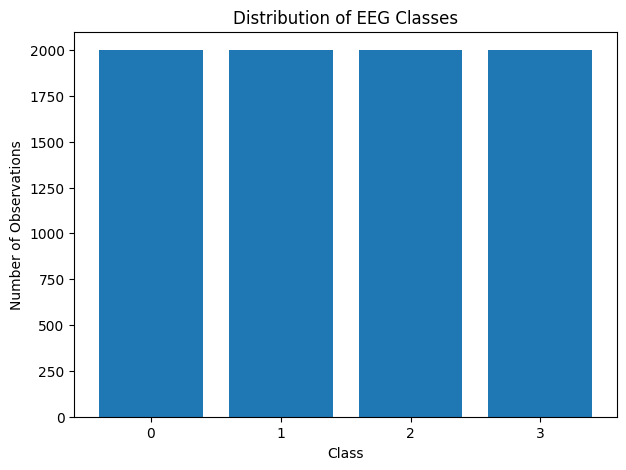

In [21]:
import matplotlib.pyplot as plt

class_counts = df['y'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(class_counts.index, class_counts.values)

plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.title("Distribution of EEG Classes")
plt.xticks([0, 1, 2, 3])

plt.show()

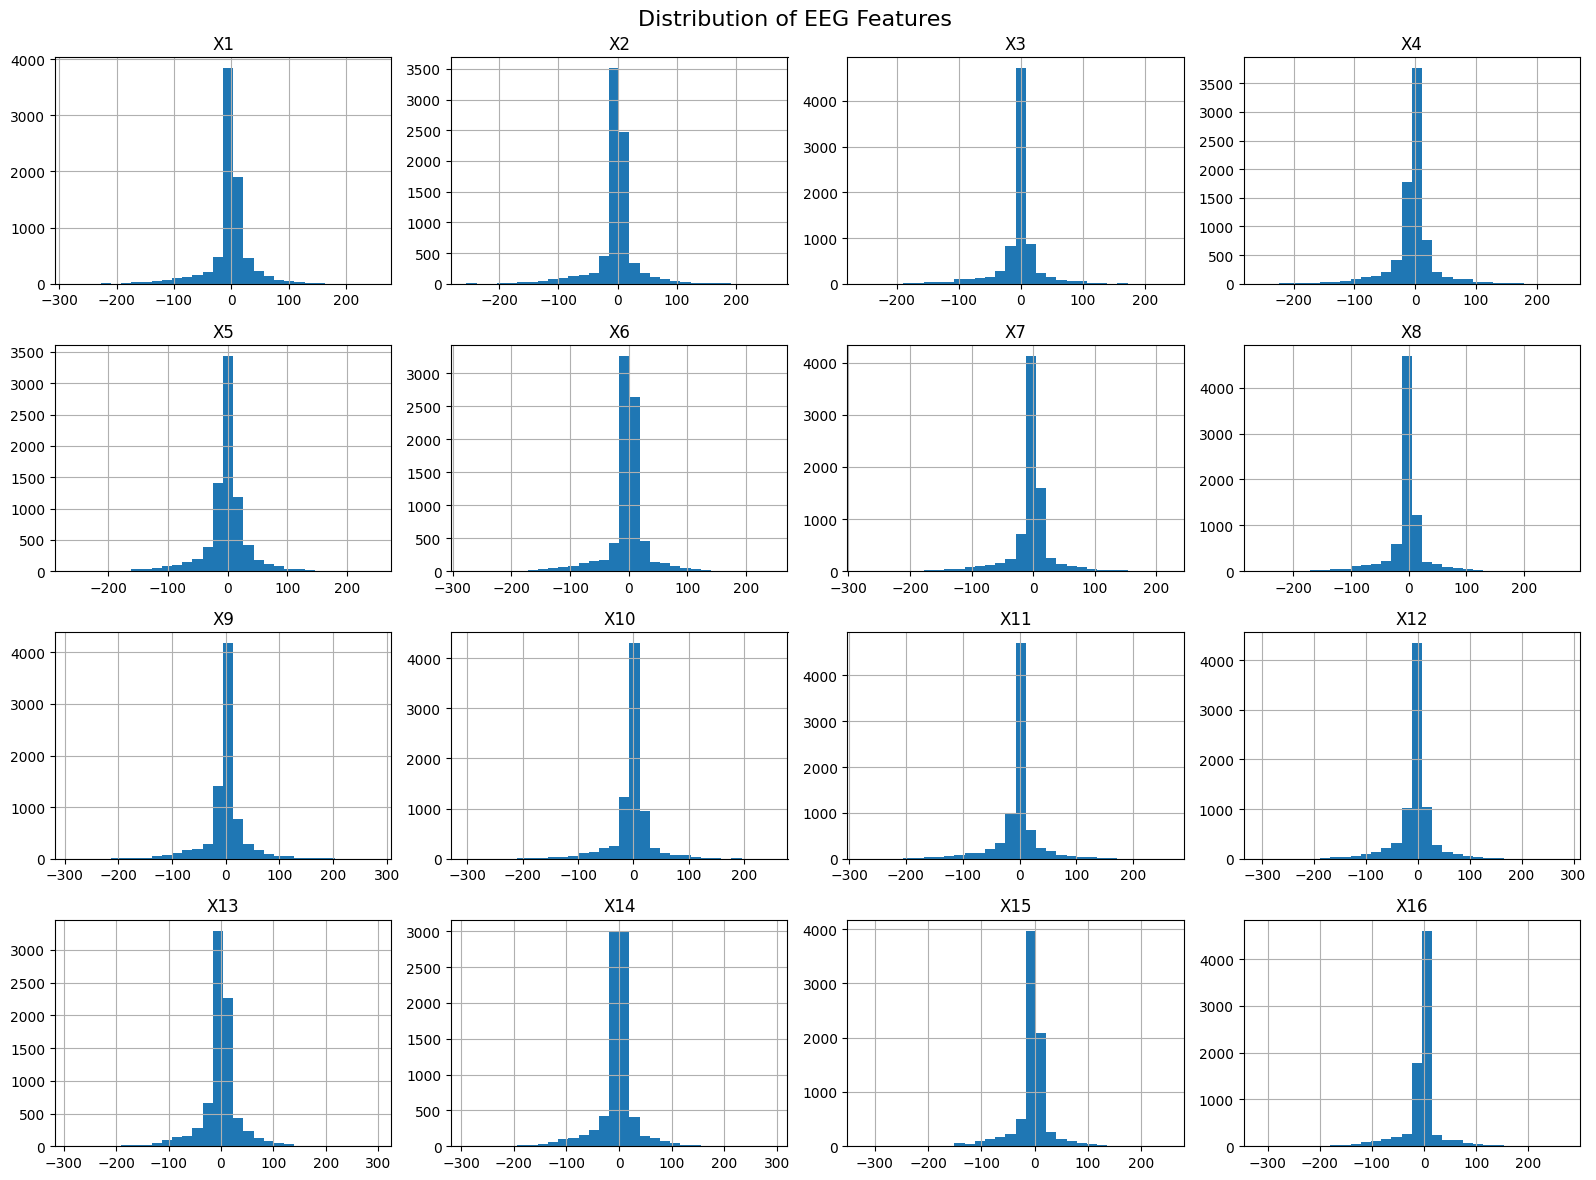

In [23]:
X_features = df.drop(columns='y')

X_features.hist(figsize=(16, 12), bins=30)

plt.suptitle("Distribution of EEG Features", fontsize=16)
plt.tight_layout()
plt.show()

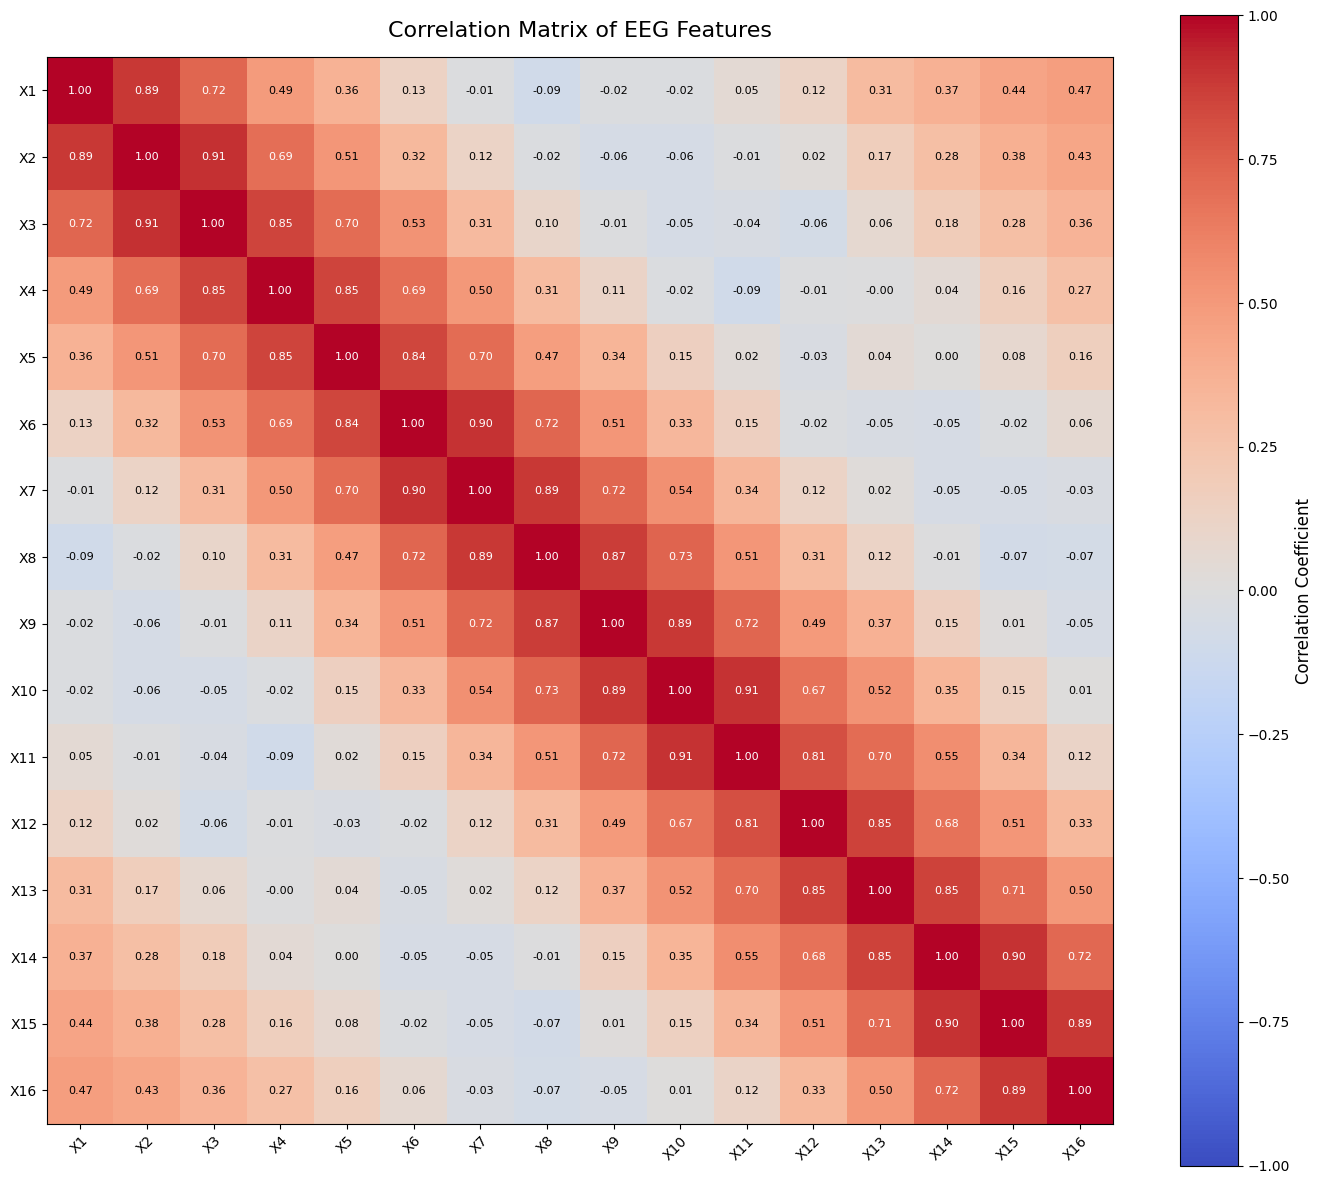

In [25]:
#Study co-relation between all 16 x values
corr = df.drop(columns='y').corr()

fig, ax = plt.subplots(figsize=(14, 12))

im = ax.imshow(
    corr,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

# Color bar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Correlation Coefficient', fontsize=12)

# Axis labels
ax.set_xticks(np.arange(len(corr.columns)))
ax.set_yticks(np.arange(len(corr.columns)))

ax.set_xticklabels(corr.columns)
ax.set_yticklabels(corr.columns)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor"
)

# Add correlation values inside each cell
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        
        value = corr.iloc[i, j]
        
        # White text for strong correlations,
        # black text for weaker correlations
        text_color = "white" if abs(value) > 0.6 else "black"
        
        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=8
        )

ax.set_title(
    "Correlation Matrix of EEG Features",
    fontsize=16,
    pad=15
)

plt.tight_layout()
plt.show()

In [27]:
#Dropping y column and keeping only features on which model should be trained
X = df.drop(columns='y')
y = df['y']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8000, 16)
y shape: (8000,)


In [29]:
from sklearn.model_selection import train_test_split

#using 80:20 split, since data has equal records for each classification using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (6400, 16)
X_test : (1600, 16)
y_train: (6400,)
y_test : (1600,)


In [31]:
print("Training set:")
print(y_train.value_counts().sort_index())

print("\nTest set:")
print(y_test.value_counts().sort_index())

Training set:
y
0    1600
1    1600
2    1600
3    1600
Name: count, dtype: int64

Test set:
y
0    400
1    400
2    400
3    400
Name: count, dtype: int64


In [33]:
#Save the test data for Github Repo
test_data = X_test.copy()

test_data['y'] = y_test.values

test_data.head()

test_data.to_csv(
    "test_data.csv",
    index=False
)

test_data.shape

(1600, 17)

In [35]:
#Logisitic regression, KNN and SVM will use scaled features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training mean:", X_train_scaled.mean())
print("Training standard deviation:", X_train_scaled.std())

Training mean: 8.500145032286355e-19
Training standard deviation: 1.0


In [37]:
#Logistic regression model
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=50,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

print(log_model.n_iter_)

y_pred_log = log_model.predict(X_test_scaled)

print("Predicted:", y_pred_log[:20])
print("Actual:   ", y_test.values[:20])

y_prob_log = log_model.predict_proba(X_test_scaled)

print(y_prob_log[:5])
print(y_prob_log[0].sum())

[42]
Predicted: [3 3 1 1 3 1 1 1 3 2 1 3 2 0 0 2 1 2 3 2]
Actual:    [3 2 1 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
[[0.24086885 0.19761998 0.27723564 0.28427553]
 [0.28265639 0.10469855 0.29903971 0.31360536]
 [0.21233045 0.30350683 0.26281814 0.22134458]
 [0.12632218 0.50845815 0.19902977 0.1661899 ]
 [0.17822027 0.22102179 0.27878673 0.3219712 ]]
1.0


In [39]:
#Baseline Logistic Regression metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

accuracy_log = accuracy_score(y_test, y_pred_log)

print("Accuracy:", accuracy_log)

precision_log = precision_score(
    y_test,
    y_pred_log,
    average='macro'
)

print("Precision:", precision_log)

recall_log = recall_score(
    y_test,
    y_pred_log,
    average='macro'
)

print("Recall:", recall_log)

f1_log = f1_score(
    y_test,
    y_pred_log,
    average='macro'
)

print("F1 Score:", f1_log)

mcc_log = matthews_corrcoef(
    y_test,
    y_pred_log
)

print("MCC:", mcc_log)

auc_log = roc_auc_score(
    y_test,
    y_prob_log,
    multi_class='ovr',
    average='macro'
)

print("AUC:", auc_log)

Accuracy: 0.454375
Precision: 0.48334468727769586
Recall: 0.454375
F1 Score: 0.46089439768017004
MCC: 0.2744087774531529
AUC: 0.657625


[[204  48  62  86]
 [ 14 238  81  67]
 [ 25  73 151 151]
 [ 22 123 121 134]]


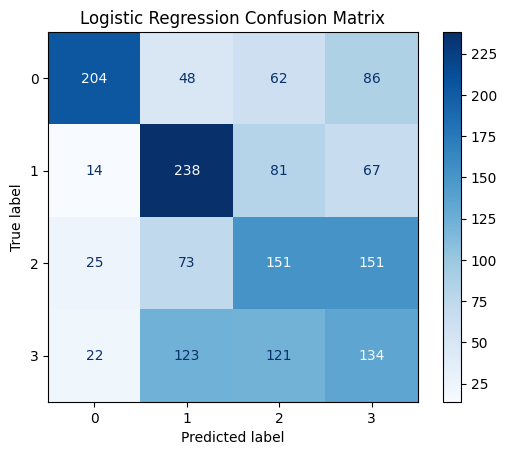

In [41]:
#Creating confusion matrix to identify how classes are misclassified
from sklearn.metrics import confusion_matrix

cm_log = confusion_matrix(y_test, y_pred_log)

print(cm_log)

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=log_model.classes_
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [43]:
##Trying different values of C and see if regularization improves model prediction

from sklearn.model_selection import cross_val_score

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

cv_scores = []

for c in C_values:
    
    model = LogisticRegression(
        C=c,
        max_iter=1000,
        random_state=42
    )
    
    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy'
    )
    
    cv_scores.append(scores.mean())

for c, score in zip(C_values, cv_scores):
    print(f"C = {c:<6}  CV Accuracy = {score:.4f}")

best_index = np.argmax(cv_scores)

best_C = C_values[best_index]

print("Best C:", best_C)
print("Best CV Accuracy:", cv_scores[best_index])

log_model_tuned = LogisticRegression(
    C=best_C,
    max_iter=1000,
    random_state=42
)

log_model_tuned.fit(X_train_scaled, y_train)

y_pred_log_tuned = log_model_tuned.predict(X_test_scaled)

y_prob_log_tuned = log_model_tuned.predict_proba(X_test_scaled)

accuracy_log_tuned = accuracy_score(
    y_test,
    y_pred_log_tuned
)

print("Original Logistic Regression Accuracy:", accuracy_log)
print("Tuned Logistic Regression Accuracy   :", accuracy_log_tuned)

C = 0.001   CV Accuracy = 0.4909
C = 0.01    CV Accuracy = 0.4889
C = 0.1     CV Accuracy = 0.4773
C = 1       CV Accuracy = 0.4722
C = 10      CV Accuracy = 0.4722
C = 100     CV Accuracy = 0.4719
Best C: 0.001
Best CV Accuracy: 0.49093749999999997
Original Logistic Regression Accuracy: 0.454375
Tuned Logistic Regression Accuracy   : 0.494375


In [45]:
# Tuned Logistic Regression metrics

accuracy_log_tuned = accuracy_score(
    y_test, y_pred_log_tuned
)

auc_log_tuned = roc_auc_score(
    y_test,
    y_prob_log_tuned,
    multi_class='ovr',
    average='macro'
)

precision_log_tuned = precision_score(
    y_test,
    y_pred_log_tuned,
    average='macro'
)

recall_log_tuned = recall_score(
    y_test,
    y_pred_log_tuned,
    average='macro'
)

f1_log_tuned = f1_score(
    y_test,
    y_pred_log_tuned,
    average='macro'
)

mcc_log_tuned = matthews_corrcoef(
    y_test,
    y_pred_log_tuned
)

print("Tuned Logistic Regression Results")
print("---------------------------------")
print(f"Accuracy  : {accuracy_log_tuned:.4f}")
print(f"AUC       : {auc_log_tuned:.4f}")
print(f"Precision : {precision_log_tuned:.4f}")
print(f"Recall    : {recall_log_tuned:.4f}")
print(f"F1 Score  : {f1_log_tuned:.4f}")
print(f"MCC       : {mcc_log_tuned:.4f}")

Tuned Logistic Regression Results
---------------------------------
Accuracy  : 0.4944
AUC       : 0.6472
Precision : 0.5021
Recall    : 0.4944
F1 Score  : 0.4869
MCC       : 0.3309


Predicted: [3 2 2 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
Actual:    [3 2 1 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
[[0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]]
Tree depth: 30
Number of leaves: 609
Training Accuracy: 1.0
Testing Accuracy: 0.875
Accuracy : 0.875
Precision: 0.8761858425670928
Recall   : 0.875
F1 Score : 0.8753864845680642
MCC      : 0.833473125445214
AUC      : 0.9166666666666667


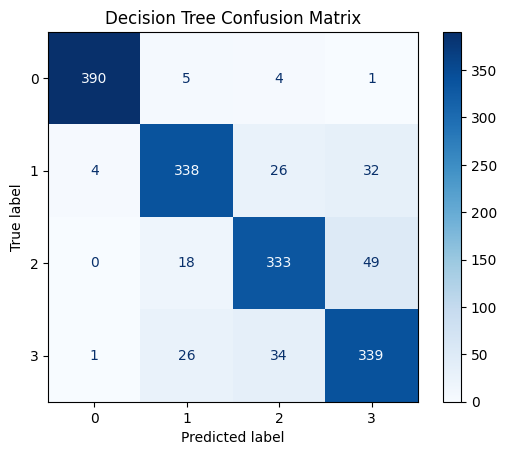

In [47]:
#Decision Tree

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Predicted:", y_pred_dt[:20])
print("Actual:   ", y_test.values[:20])

y_prob_dt = dt_model.predict_proba(X_test)

print(y_prob_dt[:5])

print("Tree depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())

print("Training Accuracy:", dt_model.score(X_train, y_train))
print("Testing Accuracy:", dt_model.score(X_test, y_test))

accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test, y_pred_dt, average='macro'
)

recall_dt = recall_score(
    y_test, y_pred_dt, average='macro'
)

f1_dt = f1_score(
    y_test, y_pred_dt, average='macro'
)

mcc_dt = matthews_corrcoef(
    y_test, y_pred_dt
)

auc_dt = roc_auc_score(
    y_test,
    y_prob_dt,
    multi_class='ovr',
    average='macro'
)

print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)
print("MCC      :", mcc_dt)
print("AUC      :", auc_dt)


cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=dt_model.classes_
)

disp.plot(cmap="Blues")

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [49]:
#Tuning of Decision Tree to find right depth and leaves to improve test accuracy
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Parameters:", dt_grid.best_params_)
print("Best CV Accuracy:", dt_grid.best_score_)

dt_model_tuned = dt_grid.best_estimator_

y_pred_dt_tuned = dt_model_tuned.predict(X_test)
y_prob_dt_tuned = dt_model_tuned.predict_proba(X_test)

accuracy_dt_tuned = accuracy_score(
    y_test,
    y_pred_dt_tuned
)

print("Original Decision Tree Accuracy :", accuracy_dt)
print("Tuned Decision Tree Accuracy    :", accuracy_dt_tuned)

print("Original depth :", dt_model.get_depth())
print("Tuned depth    :", dt_model_tuned.get_depth())

print("Original leaves:", dt_model.get_n_leaves())
print("Tuned leaves   :", dt_model_tuned.get_n_leaves())

Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Accuracy: 0.8729687500000001
Original Decision Tree Accuracy : 0.875
Tuned Decision Tree Accuracy    : 0.889375
Original depth : 30
Tuned depth    : 30
Original leaves: 609
Tuned leaves   : 518


In [51]:
# Tuned Decision Tree metrics

accuracy_dt_tuned = accuracy_score(
    y_test, y_pred_dt_tuned
)

auc_dt_tuned = roc_auc_score(
    y_test,
    y_prob_dt_tuned,
    multi_class='ovr',
    average='macro'
)

precision_dt_tuned = precision_score(
    y_test,
    y_pred_dt_tuned,
    average='macro'
)

recall_dt_tuned = recall_score(
    y_test,
    y_pred_dt_tuned,
    average='macro'
)

f1_dt_tuned = f1_score(
    y_test,
    y_pred_dt_tuned,
    average='macro'
)

mcc_dt_tuned = matthews_corrcoef(
    y_test,
    y_pred_dt_tuned
)

print("Tuned Decision Tree Results")
print("---------------------------")
print(f"Accuracy  : {accuracy_dt_tuned:.4f}")
print(f"AUC       : {auc_dt_tuned:.4f}")
print(f"Precision : {precision_dt_tuned:.4f}")
print(f"Recall    : {recall_dt_tuned:.4f}")
print(f"F1 Score  : {f1_dt_tuned:.4f}")
print(f"MCC       : {mcc_dt_tuned:.4f}")

Tuned Decision Tree Results
---------------------------
Accuracy  : 0.8894
AUC       : 0.9263
Precision : 0.8900
Recall    : 0.8894
F1 Score  : 0.8897
MCC       : 0.8525


Predicted: [3 2 1 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
Actual:    [3 2 1 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
[[0.  0.  0.  1. ]
 [0.  0.  1.  0. ]
 [0.  1.  0.  0. ]
 [0.  1.  0.  0. ]
 [0.6 0.4 0.  0. ]]
KNN Results
-----------
Accuracy  : 0.9706
AUC       : 0.9967
Precision : 0.9713
Recall    : 0.9706
F1 Score  : 0.9707
MCC       : 0.9610


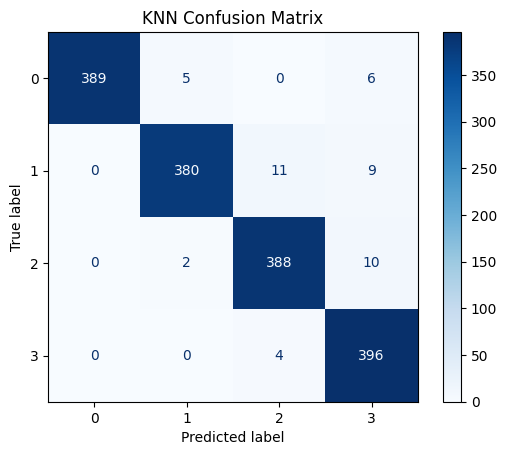

In [53]:
##KNN 
from sklearn.neighbors import KNeighborsClassifier

##After testing multiple values of k, k=4 gives the best accuracy
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print("Predicted:", y_pred_knn[:20])
print("Actual:   ", y_test.values[:20])

y_prob_knn = knn_model.predict_proba(X_test_scaled)

print(y_prob_knn[:5])

accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(
    y_test, y_pred_knn, average='macro'
)

recall_knn = recall_score(
    y_test, y_pred_knn, average='macro'
)

f1_knn = f1_score(
    y_test, y_pred_knn, average='macro'
)

mcc_knn = matthews_corrcoef(
    y_test, y_pred_knn
)

auc_knn = roc_auc_score(
    y_test,
    y_prob_knn,
    multi_class='ovr',
    average='macro'
)

print("KNN Results")
print("-----------")
print(f"Accuracy  : {accuracy_knn:.4f}")
print(f"AUC       : {auc_knn:.4f}")
print(f"Precision : {precision_knn:.4f}")
print(f"Recall    : {recall_knn:.4f}")
print(f"F1 Score  : {f1_knn:.4f}")
print(f"MCC       : {mcc_knn:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=knn_model.classes_
)

disp.plot(cmap="Blues")

plt.title("KNN Confusion Matrix")
plt.show()

In [55]:
#Find the best value for K and used tuned model for prediction

param_grid_knn = {
    'n_neighbors': range(1, 21),
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

knn_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best CV Accuracy:", knn_grid.best_score_)

knn_model_tuned = knn_grid.best_estimator_

y_pred_knn_tuned = knn_model_tuned.predict(X_test_scaled)
y_prob_knn_tuned = knn_model_tuned.predict_proba(X_test_scaled)

accuracy_knn_tuned = accuracy_score(
    y_test,
    y_pred_knn_tuned
)

print("Original KNN Accuracy:", accuracy_knn)
print("Tuned KNN Accuracy   :", accuracy_knn_tuned)

Best Parameters: {'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}
Best CV Accuracy: 0.9834375
Original KNN Accuracy: 0.970625
Tuned KNN Accuracy   : 0.98875


In [57]:
# Tuned KNN metrics

accuracy_knn_tuned = accuracy_score(
    y_test, y_pred_knn_tuned
)

auc_knn_tuned = roc_auc_score(
    y_test,
    y_prob_knn_tuned,
    multi_class='ovr',
    average='macro'
)

precision_knn_tuned = precision_score(
    y_test,
    y_pred_knn_tuned,
    average='macro'
)

recall_knn_tuned = recall_score(
    y_test,
    y_pred_knn_tuned,
    average='macro'
)

f1_knn_tuned = f1_score(
    y_test,
    y_pred_knn_tuned,
    average='macro'
)

mcc_knn_tuned = matthews_corrcoef(
    y_test,
    y_pred_knn_tuned
)

print("Tuned KNN Results")
print("-----------------")
print(f"Accuracy  : {accuracy_knn_tuned:.4f}")
print(f"AUC       : {auc_knn_tuned:.4f}")
print(f"Precision : {precision_knn_tuned:.4f}")
print(f"Recall    : {recall_knn_tuned:.4f}")
print(f"F1 Score  : {f1_knn_tuned:.4f}")
print(f"MCC       : {mcc_knn_tuned:.4f}")

Tuned KNN Results
-----------------
Accuracy  : 0.9888
AUC       : 0.9925
Precision : 0.9889
Recall    : 0.9888
F1 Score  : 0.9888
MCC       : 0.9850


Predicted: [3 2 3 1 1 1 0 1 2 2 0 2 0 0 2 2 1 2 2 2]
Actual:    [3 2 1 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
[[1.66252418e-12 7.92707413e-02 5.97822207e-02 8.60947038e-01]
 [2.08059025e-14 9.75735181e-04 8.35386315e-01 1.63637950e-01]
 [4.30187813e-13 1.32236795e-02 1.52908527e-01 8.33867794e-01]
 [2.32225000e-09 9.94224339e-01 2.56027199e-09 5.77565580e-03]
 [6.51181325e-04 9.99348785e-01 5.23501706e-30 3.37764762e-08]]
[0 1 2 3]
[1. 1. 1. 1. 1.]
Naive Bayes Results
-------------------
Accuracy  : 0.6975
AUC       : 0.9062
Precision : 0.6948
Recall    : 0.6975
F1 Score  : 0.6925
MCC       : 0.5990


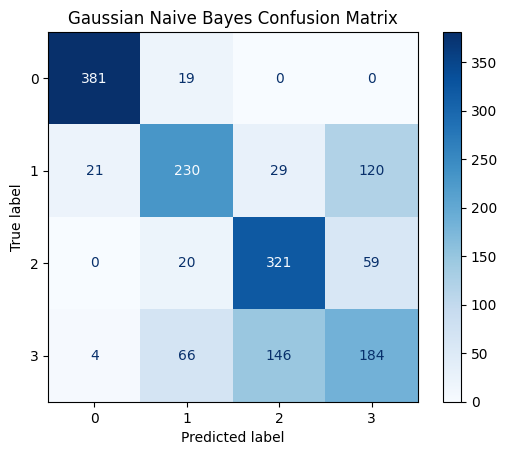

In [59]:
##Naive Bayes

##Since our features are continuous/numerical EEG measurements 
##we will use Gaussian Naive Bayes as appropriate Naive Bayes variant

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("Predicted:", y_pred_nb[:20])
print("Actual:   ", y_test.values[:20])

y_prob_nb = nb_model.predict_proba(X_test)

print(y_prob_nb[:5])

print(nb_model.classes_)
print(y_prob_nb[:5].sum(axis=1))

accuracy_nb = accuracy_score(y_test, y_pred_nb)

precision_nb = precision_score(
    y_test,
    y_pred_nb,
    average='macro'
)

recall_nb = recall_score(
    y_test,
    y_pred_nb,
    average='macro'
)

f1_nb = f1_score(
    y_test,
    y_pred_nb,
    average='macro'
)

mcc_nb = matthews_corrcoef(
    y_test,
    y_pred_nb
)

auc_nb = roc_auc_score(
    y_test,
    y_prob_nb,
    multi_class='ovr',
    average='macro'
)

print("Naive Bayes Results")
print("-------------------")
print(f"Accuracy  : {accuracy_nb:.4f}")
print(f"AUC       : {auc_nb:.4f}")
print(f"Precision : {precision_nb:.4f}")
print(f"Recall    : {recall_nb:.4f}")
print(f"F1 Score  : {f1_nb:.4f}")
print(f"MCC       : {mcc_nb:.4f}")


cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=nb_model.classes_
)

disp.plot(cmap="Blues")

plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()

In [61]:
#Tune GNB using var_smoothing hyperparameter and 5-fold cross-validation

param_grid_nb = {
    'var_smoothing': np.logspace(-12, -5, 50)
}

nb_grid = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid_nb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

nb_grid.fit(X_train, y_train)

print("Best var_smoothing:", nb_grid.best_params_)
print("Best CV Accuracy:", nb_grid.best_score_)

nb_model_tuned = nb_grid.best_estimator_

y_pred_nb_tuned = nb_model_tuned.predict(X_test)

y_prob_nb_tuned = nb_model_tuned.predict_proba(X_test)

accuracy_nb_tuned = accuracy_score(
    y_test,
    y_pred_nb_tuned
)

print("Original GNB Accuracy:", accuracy_nb)
print("Tuned GNB Accuracy   :", accuracy_nb_tuned)

Best var_smoothing: {'var_smoothing': np.float64(1e-12)}
Best CV Accuracy: 0.7165625000000001
Original GNB Accuracy: 0.6975
Tuned GNB Accuracy   : 0.6975


Since there is no improvement in accuracy based on var_smoothing hyper parameter using baseline metrics in comparison table

/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Predicted: [2 2 2 1 0 1 1 1 2 2 0 2 0 0 2 2 1 2 2 2]
Actual:    [3 2 1 1 0 1 1 3 2 2 0 3 0 0 2 2 1 2 2 2]
[[9.57841104e-04 3.20185868e-01 1.96963553e-01 4.81892738e-01]
 [7.34979815e-04 2.56917448e-02 5.96602451e-01 3.76970824e-01]
 [1.67167911e-03 2.16936016e-01 4.14094903e-01 3.67297402e-01]
 [4.13071132e-03 8.51905044e-01 3.88786333e-03 1.40076381e-01]
 [9.95322888e-01 3.99776575e-03 2.88741320e-04 3.90604867e-04]]
[0 1 2 3]
[1. 1. 1. 1. 1.]
SVM Results
-----------
Accuracy  : 0.7444
AUC       : 0.9272
Precision : 0.7731
Recall    : 0.7444
F1 Score  : 0.7310
MCC       : 0.6791


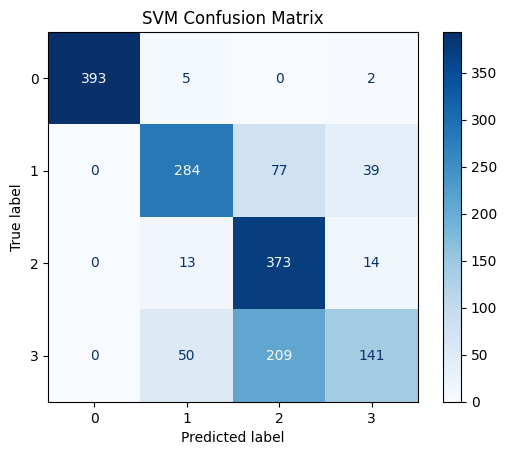

In [63]:
##SVM

from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("Predicted:", y_pred_svm[:20])
print("Actual:   ", y_test.values[:20])

y_prob_svm = svm_model.predict_proba(X_test_scaled)

print(y_prob_svm[:5])

print(svm_model.classes_)
print(y_prob_svm[:5].sum(axis=1))

accuracy_svm = accuracy_score(
    y_test, y_pred_svm
)

precision_svm = precision_score(
    y_test, y_pred_svm, average='macro'
)

recall_svm = recall_score(
    y_test, y_pred_svm, average='macro'
)

f1_svm = f1_score(
    y_test, y_pred_svm, average='macro'
)

mcc_svm = matthews_corrcoef(
    y_test, y_pred_svm
)

auc_svm = roc_auc_score(
    y_test,
    y_prob_svm,
    multi_class='ovr',
    average='macro'
)

print("SVM Results")
print("-----------")
print(f"Accuracy  : {accuracy_svm:.4f}")
print(f"AUC       : {auc_svm:.4f}")
print(f"Precision : {precision_svm:.4f}")
print(f"Recall    : {recall_svm:.4f}")
print(f"F1 Score  : {f1_svm:.4f}")
print(f"MCC       : {mcc_svm:.4f}")

cm_svm = confusion_matrix(
    y_test,
    y_pred_svm
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=svm_model.classes_
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.show()

In [65]:
#Generate classification report to see despite high AUC why we still have less accuracy
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_svm,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     1.0000    0.9825    0.9912       400
           1     0.8068    0.7100    0.7553       400
           2     0.5660    0.9325    0.7044       400
           3     0.7194    0.3525    0.4732       400

    accuracy                         0.7444      1600
   macro avg     0.7731    0.7444    0.7310      1600
weighted avg     0.7731    0.7444    0.7310      1600



In [67]:
#Baseline SVM has poor recall for Class3, we will tune SVM using GridsearchCV with 5 fold cross-validation
#Focusing on C and gamma 
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

svm_grid = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid_svm,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)
#Added this to remove future warning that is appearing for scikit-learn regarding probability parameter to have clean output 
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)

svm_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", svm_grid.best_params_)
print("Best CV Macro F1:", svm_grid.best_score_)

#For probability used this custom approach as we turned off probability =true from svm_grid to suppress future warning as mentioned
from sklearn.calibration import CalibratedClassifierCV

best_svm = SVC(
    C=svm_grid.best_params_['C'],
    gamma=svm_grid.best_params_['gamma'],
    kernel=svm_grid.best_params_['kernel']
)

svm_model_tuned = CalibratedClassifierCV(
    best_svm,
    method='sigmoid',
    cv=5
)

svm_model_tuned.fit(X_train_scaled, y_train)

y_pred_svm_tuned = svm_model_tuned.predict(X_test_scaled)

y_prob_svm_tuned = svm_model_tuned.predict_proba(X_test_scaled)

print(y_pred_svm_tuned[:5])
print(y_prob_svm_tuned[:5])
print(y_prob_svm_tuned[:5].sum(axis=1))

accuracy_svm_tuned = accuracy_score(
    y_test, y_pred_svm_tuned
)

auc_svm_tuned = roc_auc_score(
    y_test,
    y_prob_svm_tuned,
    multi_class='ovr',
    average='macro'
)

precision_svm_tuned = precision_score(
    y_test,
    y_pred_svm_tuned,
    average='macro'
)

recall_svm_tuned = recall_score(
    y_test,
    y_pred_svm_tuned,
    average='macro'
)

f1_svm_tuned = f1_score(
    y_test,
    y_pred_svm_tuned,
    average='macro'
)

mcc_svm_tuned = matthews_corrcoef(
    y_test,
    y_pred_svm_tuned
)

print("Tuned SVM Results")
print("-----------------")
print(f"Accuracy  : {accuracy_svm_tuned:.4f}")
print(f"AUC       : {auc_svm_tuned:.4f}")
print(f"Precision : {precision_svm_tuned:.4f}")
print(f"Recall    : {recall_svm_tuned:.4f}")
print(f"F1 Score  : {f1_svm_tuned:.4f}")
print(f"MCC       : {mcc_svm_tuned:.4f}")

#Classification report to see how Class 3 classification improved
print(
    classification_report(
        y_test,
        y_pred_svm_tuned,
        digits=4
    )
)

Best Parameters: {'C': 100, 'gamma': 1, 'kernel': 'rbf'}
Best CV Macro F1: 0.9723148960702016
[3 2 1 1 0]
[[3.92738881e-09 2.22011167e-01 1.78353828e-04 7.77810476e-01]
 [3.85628195e-09 4.54502617e-06 9.65891224e-01 3.41042267e-02]
 [3.94569960e-09 9.58687504e-01 1.50492399e-04 4.11619996e-02]
 [5.01108941e-06 9.81614890e-01 1.77603770e-06 1.83783229e-02]
 [9.67360061e-01 3.25754962e-02 1.86328332e-06 6.25791762e-05]]
[1. 1. 1. 1. 1.]
Tuned SVM Results
-----------------
Accuracy  : 0.9881
AUC       : 0.9981
Precision : 0.9882
Recall    : 0.9881
F1 Score  : 0.9882
MCC       : 0.9842
              precision    recall  f1-score   support

           0     1.0000    0.9975    0.9987       400
           1     1.0000    0.9850    0.9924       400
           2     0.9753    0.9875    0.9814       400
           3     0.9776    0.9825    0.9800       400

    accuracy                         0.9881      1600
   macro avg     0.9882    0.9881    0.9882      1600
weighted avg     0.9882    0.98

In [69]:
#We will generate comparison table with tuned models-LR,Decision Tree, KNN, SVM
#Use baseline metrics from GNB
comparison_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'SVM'
    ],

    'Accuracy': [
        accuracy_log_tuned,
        accuracy_dt_tuned,
        accuracy_knn_tuned,
        accuracy_nb,          
        accuracy_svm_tuned
    ],

    'AUC': [
        auc_log_tuned,
        auc_dt_tuned,
        auc_knn_tuned,
        auc_nb,              
        auc_svm_tuned
    ],

    'Precision': [
        precision_log_tuned,
        precision_dt_tuned,
        precision_knn_tuned,
        precision_nb,         
        precision_svm_tuned
    ],

    'Recall': [
        recall_log_tuned,
        recall_dt_tuned,
        recall_knn_tuned,
        recall_nb,            
        recall_svm_tuned
    ],

    'F1 Score': [
        f1_log_tuned,
        f1_dt_tuned,
        f1_knn_tuned,
        f1_nb,                
        f1_svm_tuned
    ],

    'MCC': [
        mcc_log_tuned,
        mcc_dt_tuned,
        mcc_knn_tuned,
        mcc_nb,               
        mcc_svm_tuned
    ]
})

comparison_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.4944,0.6472,0.5021,0.4944,0.4869,0.3309
1,Decision Tree,0.8894,0.9262,0.8900,0.8894,0.8897,0.8525
2,KNN,0.9888,0.9925,0.9889,0.9888,0.9888,0.9850
3,Gaussian Naive Bayes,0.6975,0.9062,0.6948,0.6975,0.6925,0.5990
4,SVM,0.9881,0.9981,0.9882,0.9881,0.9882,0.9842


In [77]:
#Save all models to project folder
import os

os.makedirs("model", exist_ok=True)

print(os.getcwd())

#save all the models
import joblib

joblib.dump(
    log_model_tuned,
    "model/logistic_regression.joblib"
)

joblib.dump(
    dt_model_tuned,
    "model/decision_tree.joblib"
)

joblib.dump(
    knn_model_tuned,
    "model/knn.joblib"
)

joblib.dump(
    nb_model,
    "model/gaussian_nb.joblib"
)

joblib.dump(
    svm_model_tuned,
    "model/svm.joblib"
)

#save preprocessing scalar
joblib.dump(
    scaler,
    "model/scaler.joblib"
)


#verify all files exist
for file in os.listdir("model"):
    print(file)

/home/s2026ak05219/workspace/BEED-EEG-Classification
gaussian_nb.joblib
scaler.joblib
svm.joblib
logistic_regression.joblib
decision_tree.joblib
knn.joblib


In [79]:
#Verify saved models reload correctly and test one observation
log_test = joblib.load(
    "model/logistic_regression.joblib"
)

dt_test = joblib.load(
    "model/decision_tree.joblib"
)

knn_test = joblib.load(
    "model/knn.joblib"
)

nb_test = joblib.load(
    "model/gaussian_nb.joblib"
)

svm_test = joblib.load(
    "model/svm.joblib"
)

scaler_test = joblib.load(
    "model/scaler.joblib"
)

#Test observation
sample = X_test.iloc[[0]]

sample_scaled = scaler_test.transform(sample)

print(
    "Logistic Regression:",
    log_test.predict(sample_scaled)
)

print(
    "Decision Tree:",
    dt_test.predict(sample)
)

print(
    "KNN:",
    knn_test.predict(sample_scaled)
)

print(
    "Gaussian NB:",
    nb_test.predict(sample)
)

print(
    "SVM:",
    svm_test.predict(sample_scaled)
)

Logistic Regression: [1]
Decision Tree: [3]
KNN: [3]
Gaussian NB: [3]
SVM: [3]
